This portion of the code attempts to do a full PSO search over the search space

First we need to extract the interleaved 24-port Tx/Rx parameters from the `.s24p` (TouchStone) file.

In [1]:
import numpy as np
import skrf as rf

fc = 3.5e9

ntwk = rf.Network("../data/Tx_1x24_RP_HFSSDesign1.s24p")

freq_idx = np.argmin(np.abs(ntwk.f - fc))
S = ntwk.s[freq_idx]

tx_idx = np.arange(0, 24, 2)
rx_idx = np.arange(1, 24, 2)

H_si = S[np.ix_(rx_idx, tx_idx)]

print(H_si.shape)   # (12, 12)

(12, 12)


Tx-to-Tx/Rx-to-Rx spacing is 0.08m (8cm) so each antenna element has a spacing of 0.04m (4cm) with adjacent elements

The resulting self-interference channel is therefore
$$
H_{\mathrm{SI}} \in \mathbb{C}^{12\times 12}.
$$
Conceptually, if the full scattering matrix is
$$
S \in \mathbb{C}^{24\times 24},
$$

it can be viewed as containing four different coupling blocks:

$$
S =
\begin{bmatrix}
S_{\mathrm{TX}\to\mathrm{TX}} &
S_{\mathrm{RX}\to\mathrm{TX}} \\[4pt]
S_{\mathrm{TX}\to\mathrm{RX}} &
S_{\mathrm{RX}\to\mathrm{RX}}
\end{bmatrix}.
$$

The self-interference channel of interest is the coupling from the transmit ports to the receive ports,

$$
H_{\mathrm{SI}}
=
S_{\mathrm{TX}\to\mathrm{RX}},
$$

which has dimensions

$$
H_{\mathrm{SI}} \in \mathbb{C}^{12\times 12}.
\]
$$

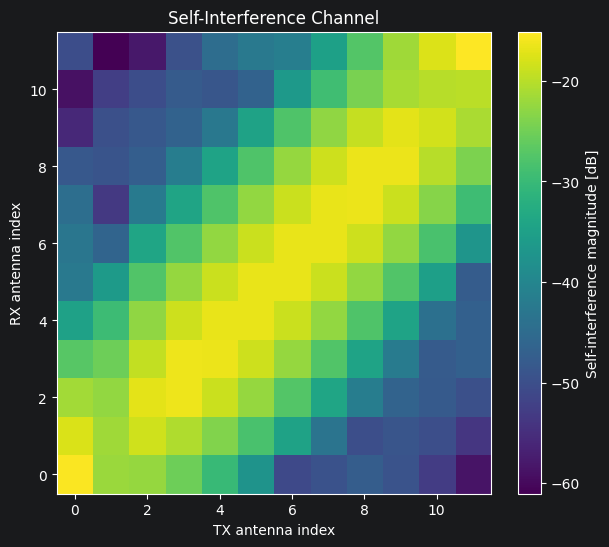

In [2]:
# we seek to visualize the amplitude of Hsi over the antenna array pairs (Rxi,Txi)

import numpy as np
import matplotlib.pyplot as plt

# H_si is your complex self-interference matrix
# shape: (N_rx, N_tx)

H_si_dB = 20 * np.log10(np.abs(H_si) + 1e-12)

plt.figure(figsize=(7, 6))

plt.imshow(
    H_si_dB,
    aspect="auto",
    origin="lower"
)

plt.colorbar(label="Self-interference magnitude [dB]")

plt.xlabel("TX antenna index")
plt.ylabel("RX antenna index")
plt.title("Self-Interference Channel")

plt.show()

The PSO-search optimizes the function $f(r_{Tx},\theta_{Tx},\phi_{Tx},r_{Rx},\theta_{Rx},\phi_{Rx}) \rightarrow SI_{dB}$ which is a function that maps $\mathbb{R^6}$ to $\mathbb{R}$



In [3]:
def make_ula_positions(num_elements, element_spacing):
    coord = (
        np.arange(num_elements)
        - (num_elements - 1) / 2
    ) * element_spacing

    return np.stack([
        np.zeros(num_elements),
        coord,
        np.zeros(num_elements)
    ], axis=1)


full_pos = make_ula_positions(
    num_elements=24,
    element_spacing=0.04
)

pos_tx = full_pos[tx_idx]
pos_rx = full_pos[rx_idx]

In [4]:
pos_tx.shape

(12, 3)

$\vec{p} = [x_n,y_n,z_n]$ so 12x3, 12 because there are 12 Tx and 12Rx elements and 3 for each cartesian coordinate

In [5]:
def sph_to_cart(r, phi_deg, theta_deg):
    phi = np.deg2rad(phi_deg)
    theta = np.deg2rad(theta_deg)

    x = r * np.cos(theta) * np.cos(phi)
    y = r * np.cos(theta) * np.sin(phi)
    z = r * np.sin(theta)

    return np.array([x, y, z])

In [6]:
# define the UL/DL user locations
case = {
    #downlink coordinates
    "r_dl_user": 3.0,
    "phi_dl_user": 20.0,
    "theta_dl_user": 0.0,

    #uplink coordinates
    "r_ul_user": 4.0,
    "phi_ul_user": -25.0,
    "theta_ul_user": 0.0,

    "seed": 1234
}

ul_user = (case["r_ul_user"],case["phi_ul_user"],case["theta_ul_user"])
dl_user = (case["r_dl_user"],case["phi_dl_user"],case["theta_dl_user"])

dl_user_pos = (
    case["r_dl_user"],
    case["phi_dl_user"],
    case["theta_dl_user"]
)

ul_user_pos = (
    case["r_ul_user"],
    case["phi_ul_user"],
    case["theta_ul_user"]
)

Channel vector :
$$
h_n(r,\phi,\theta)
=
\frac{r}{d_n}
e^{-jk(d_n-r)}
$$

PSO workflow :

$$
\underbrace{
\begin{bmatrix}
r_{\mathrm{tx}} \\
\phi_{\mathrm{tx}} \\
\theta_{\mathrm{tx}} \\
r_{\mathrm{rx}} \\
\phi_{\mathrm{rx}} \\
\theta_{\mathrm{rx}}
\end{bmatrix}
}_{\text{PSO particle}}
\longrightarrow
\underbrace{
\begin{matrix}
\mathbf{h}_{\mathrm{tx}} \\
\mathbf{h}_{\mathrm{rx}}
\end{matrix}
}_{\text{near-field channels}}
\longrightarrow
\underbrace{
\begin{matrix}
\mathbf{w}_{\mathrm{tx}}
=
\frac{\mathbf{h}_{\mathrm{tx}}^{*}}
{\|\mathbf{h}_{\mathrm{tx}}\|_2}
\\[8pt]
\mathbf{w}_{\mathrm{rx}}
=
\frac{\mathbf{h}_{\mathrm{rx}}^{*}}
{\|\mathbf{h}_{\mathrm{rx}}\|_2}
\end{matrix}
}_{\text{beamforming weights}}
\longrightarrow
\underbrace{
\mathbf{w}_{\mathrm{rx}}^{H}
\mathbf{H}_{\mathrm{SI}}
\mathbf{w}_{\mathrm{tx}}
}_{\text{effective SI channel}}
\longrightarrow
\underbrace{
20\log_{10}
\left|
\mathbf{w}_{\mathrm{rx}}^{H}
\mathbf{H}_{\mathrm{SI}}
\mathbf{w}_{\mathrm{tx}}
\right|
}_{SI_{\mathrm{dB}}}
\longrightarrow
\underbrace{
J
}_{\text{PSO objective}}
$$

In [7]:
def near_field_channel(pos_elem, r, phi_deg, theta_deg, fc):
    c = 3e8
    wavelength = c / fc
    k = 2 * np.pi / wavelength

    focus = sph_to_cart(
        r,
        phi_deg,
        theta_deg
    )

    # distance from each antenna element to the focus point
    distances = np.linalg.norm(
        pos_elem - focus,
        axis=1
    )

    # near-field channel vector
    h = (
        (r / distances)
        * np.exp(
            -1j * k * (distances - r)
        )
    )

    return h

def get_SI(particle):
    r_tx, phi_tx, theta_tx, r_rx, phi_rx, theta_rx = particle

    # Tx near-field channel vector
    h_tx = near_field_channel(
        pos_tx,
        r_tx,
        phi_tx,
        theta_tx,
        fc
    )

    # Rx near-field channel vector
    h_rx = near_field_channel(
        pos_rx,
        r_rx,
        phi_rx,
        theta_rx,
        fc
    )

    # Conjugate beamforming weights
    w_tx = np.conj(h_tx) / np.linalg.norm(h_tx)
    w_rx = np.conj(h_rx) / np.linalg.norm(h_rx)

    # Effective self-interference channel
    si = w_rx.conj().T @ H_si @ w_tx

    # Convert magnitude to dB
    si_db = 20 * np.log10(
        np.abs(si) + 1e-15
    )

    return si_db

def user_gain(pos_elem, focus, user):
    """
    Power gain at `user` when the array is focused at `focus`.
    """

    r_f, phi_f, theta_f = focus
    r_u, phi_u, theta_u = user

    # Beamforming weights created from chosen focus
    h_focus = near_field_channel(
        pos_elem,
        r_f,
        phi_f,
        theta_f,
        fc
    )

    w = np.conj(h_focus) / np.linalg.norm(h_focus)

    # Actual channel to the user
    h_user = near_field_channel(
        pos_elem,
        r_u,
        phi_u,
        theta_u,
        fc
    )

    gain = np.abs(h_user @ w) ** 2

    return 10 * np.log10(gain + 1e-15)

G_dl_ref = user_gain(
    pos_tx,
    dl_user_pos,
    dl_user_pos
)

G_ul_ref = user_gain(
    pos_rx,
    ul_user_pos,
    ul_user_pos
)

def objective_function(particle):

    r_tx, phi_tx, theta_tx, r_rx, phi_rx, theta_rx = particle

    tx_focus_pos = (r_tx, phi_tx, theta_tx)
    rx_focus_pos = (r_rx, phi_rx, theta_rx)

    # Original SI objective
    si_db = get_SI(particle)

    # Desired-link gains
    G_dl = user_gain(
    pos_tx,
    tx_focus_pos,
    dl_user_pos
    )

    G_ul = user_gain(
        pos_rx,
        rx_focus_pos,
        ul_user_pos
    )

    # Loss relative to focusing directly on each user
    loss_dl = G_dl_ref - G_dl
    loss_ul = G_ul_ref - G_ul

    # Violation only after 3 dB loss
    v_dl = max(0.0, loss_dl - 3.0)
    v_ul = max(0.0, loss_ul - 3.0)

    penalty_weight = 20.0

    penalty = penalty_weight * (
        v_dl + v_ul
    )

    return si_db + penalty


Note :  *NumPy broadcasting* makes it easier to handle numpy arrays of different dimensions

In [8]:
rng = np.random.default_rng(42)
class PSO:
    def __init__(self,reference_position):

        self.inertia = 0.72
        self.cognitive = 1.45
        self.social = 1.45

        self.n_particles = 48
        self.n_dimensions = 6

        # Example bounds:
        # [r_tx, phi_tx, theta_tx, r_rx, phi_rx, theta_rx]
        self.lower = np.array([
            0.5, -90, -30,
            0.5, -90, -30
        ])

        self.upper = np.array([
            8.0, 90, 30,
            8.0, 90, 30
        ])

        # shape = (48, 6)
        self.positions = rng.uniform(
            low=self.lower,
            high=self.upper,
            size=(self.n_particles, self.n_dimensions)
        )

        self.positions[0] = reference_position

        # same shape as positions
        #NEW initialized random velocities instead of zero to force exploration and scaled them by the span
        span = self.upper - self.lower

        self.velocities = rng.uniform(
            low=-0.1 * span,
            high=0.1 * span,
            size=(self.n_particles, self.n_dimensions)
        )

        # Initially, each particle's current position
        # is its personal best
        self.personal_best_positions = self.positions.copy()

        # Objective values of personal bests
        self.personal_best_scores = np.full(
            self.n_particles,
            np.inf
        )

        self.global_best_position = None
        self.global_best_score = np.inf

    def evaluate(self, objective_function):

        for i in range(self.n_particles):

            score = objective_function(
                self.positions[i]
            )

            # update personal best
            if score < self.personal_best_scores[i]:

                self.personal_best_scores[i] = score

                self.personal_best_positions[i] = (
                    self.positions[i].copy()
                )

        # find best personal best in the swarm
        best_index = np.argmin(
            self.personal_best_scores
        )

        self.global_best_score = (
            self.personal_best_scores[best_index]
        )

        self.global_best_position = (
            self.personal_best_positions[best_index].copy()
        )

    def step(self, iteration, n_iterations):

        w_max = 0.9
        w_min = 0.4

        inertia = (
            w_max
            - (w_max - w_min)
            * iteration / n_iterations
        )

        r1 = rng.random(
            size=(self.n_particles, self.n_dimensions)
        )

        r2 = rng.random(
            size=(self.n_particles, self.n_dimensions)
        )

        personal_term = (
            self.personal_best_positions
            - self.positions
        )

        global_term = (
            self.global_best_position
            - self.positions
        )

        #TODO implement a decaying inertia to promote convergence if needed

        self.velocities = (
            self.inertia * self.velocities
            + self.cognitive * r1 * personal_term
            + self.social * r2 * global_term
        )

        max_velocity = 0.25 * (
            self.upper - self.lower
        )

        self.velocities = np.clip(
            self.velocities,
            -max_velocity,
            max_velocity
        )

        self.positions += self.velocities

        self.positions = np.clip(
            self.positions,
            self.lower,
            self.upper
        )
    def optimize(self, objective_function, n_iterations=90):
        history = []

        # Evaluate initial swarm
        self.evaluate(objective_function)

        for iteration in range(n_iterations):

            self.step(
                iteration,
                n_iterations
            )

            self.evaluate(objective_function)

            history.append(self.global_best_score)

            print(
                f"Iteration {iteration:3d} | "
                f"Best SI = {self.global_best_score:.3f} dB"
            )

        return (
            self.global_best_position,
            self.global_best_score,
            history
        )


In [9]:
reference_position = np.array([
    case["r_dl_user"],
    case["phi_dl_user"],
    case["theta_dl_user"],
    case["r_ul_user"],
    case["phi_ul_user"],
    case["theta_ul_user"]
])

pso = PSO(
    reference_position=reference_position
)

best_position, best_si_db, history = pso.optimize(
    objective_function,
    n_iterations=300
)

best_si_db = get_SI(best_position)

Iteration   0 | Best SI = -35.074 dB
Iteration   1 | Best SI = -35.074 dB
Iteration   2 | Best SI = -35.074 dB
Iteration   3 | Best SI = -35.797 dB
Iteration   4 | Best SI = -35.797 dB
Iteration   5 | Best SI = -35.797 dB
Iteration   6 | Best SI = -38.326 dB
Iteration   7 | Best SI = -38.326 dB
Iteration   8 | Best SI = -38.326 dB
Iteration   9 | Best SI = -40.928 dB
Iteration  10 | Best SI = -40.928 dB
Iteration  11 | Best SI = -40.928 dB
Iteration  12 | Best SI = -40.928 dB
Iteration  13 | Best SI = -40.928 dB
Iteration  14 | Best SI = -40.928 dB
Iteration  15 | Best SI = -40.928 dB
Iteration  16 | Best SI = -40.928 dB
Iteration  17 | Best SI = -41.482 dB
Iteration  18 | Best SI = -43.352 dB
Iteration  19 | Best SI = -43.352 dB
Iteration  20 | Best SI = -44.361 dB
Iteration  21 | Best SI = -44.361 dB
Iteration  22 | Best SI = -44.361 dB
Iteration  23 | Best SI = -44.361 dB
Iteration  24 | Best SI = -45.785 dB
Iteration  25 | Best SI = -46.514 dB
Iteration  26 | Best SI = -46.514 dB
I

Note : A higher absolute $|SI_{dB}|$ value means weaker self-interference

Interpretation :
The blue cross corresponds to the _desired Tx focus point_

The main lobe _does_ pass through the desired focus, and the -3dB contour encloses the strongest region.

Beam focusing seems effective

Could the secondary lobe be a _grating lobe_ ?

In [10]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("../").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np

from src.env import NearFieldBeamFocusingEnv
from src.config import ENV_CONFIG

from src.test_3d_beam_map import (
    plot_3d_geometry,
    user_from_case
)

import matplotlib.pyplot as plt

# Prevent Jupyter from trying to display figures
plt.ioff()

In [11]:
env_config = ENV_CONFIG.copy()
env_config["seed"] = 1234

env = NearFieldBeamFocusingEnv(
    S, # we give it the original S-parameters (24x24) not the extracted Tx-Rx array
    **env_config
)

In [12]:
r_tx, phi_tx, theta_tx, r_rx, phi_rx, theta_rx = best_position

In [13]:
tx_focus = {
    "r": float(r_tx),
    "phi": float(phi_tx),
    "theta": float(theta_tx)
}

rx_focus = {
    "r": float(r_rx),
    "phi": float(phi_rx),
    "theta": float(theta_rx)
}

In [14]:
dl_user_plot = user_from_case(case, "dl")
ul_user_plot = user_from_case(case, "ul")

In [15]:
fig = plt.figure(
    figsize=(10, 8)
)

ax = fig.add_subplot(
    111,
    projection="3d"
)

plot_3d_geometry(
    ax=ax,
    env=env,
    tx_user=dl_user_plot,
    rx_user=ul_user_plot,
    tx_focus=tx_focus,
    rx_focus=rx_focus,
    resolution=64,
    title=(
        f"PSO Beam Focusing\n"
        f"Best SI = {best_si_db:.2f} dB"
    )
)

output_file = "pso_beam_focusing_3d.png"

fig.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig)

print(f"Saved to: {output_file}")

Saved to: pso_beam_focusing_3d.png


In [16]:
print("Best position:", best_position)
print("Best actual SI:", best_si_db)

r_tx, phi_tx, theta_tx, r_rx, phi_rx, theta_rx = best_position

tx_focus_pos = (
    r_tx,
    phi_tx,
    theta_tx
)

rx_focus_pos = (
    r_rx,
    phi_rx,
    theta_rx
)

G_dl = user_gain(
    pos_tx,
    tx_focus_pos,
    dl_user
)

G_ul = user_gain(
    pos_rx,
    rx_focus_pos,
    ul_user
)

loss_dl = G_dl_ref - G_dl
loss_ul = G_ul_ref - G_ul

print(f"DL reference gain : {G_dl_ref:.3f} dB")
print(f"DL final gain     : {G_dl:.3f} dB")
print(f"DL gain loss      : {loss_dl:.3f} dB")

print()

print(f"UL reference gain : {G_ul_ref:.3f} dB")
print(f"UL final gain     : {G_ul:.3f} dB")
print(f"UL gain loss      : {loss_ul:.3f} dB")

print()

print("DL feasible:", loss_dl <= 3.0)
print("UL feasible:", loss_ul <= 3.0)

Best position: [  7.75262319 -45.94529469   5.23901912   1.95099629 -23.41670122
  -8.74787589]
Best actual SI: -58.39349853162351
DL reference gain : 10.753 dB
DL final gain     : 9.094 dB
DL gain loss      : 1.658 dB

UL reference gain : 10.768 dB
UL final gain     : 7.768 dB
UL gain loss      : 3.000 dB

DL feasible: True
UL feasible: True


Maybe the next step would be to implement a "hard" rule like $$|\phi_{\text{focus}} - \phi_{\text{user}} \le \frac{HPBW}{2}|$$